# Drag-Level Mouse Dynamics Model

This notebook builds a baseline model to predict whether a user is using the **left** or **right** hand from the **drag-level** mouse dynamics dataset.

## Important note
Because drag-level data contains multiple rows from the same attempt, this notebook uses a **grouped train-test split by `AttemptID`** to reduce data leakage.


## 1. Import libraries

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay


## 2. Load the dataset

In [9]:
# Update the file path if needed
file_path = 'Drag Level Combined.xlsx'

if file_path.endswith('.csv'):
    df = pd.read_csv(file_path)
elif file_path.endswith('.xlsx') or file_path.endswith('.xls'):
    df = pd.read_excel(file_path)
else:
    raise ValueError('Unsupported file format')
    
print('Shape:', df.shape)
print('\nColumns:')
print(df.columns.tolist())

df.head()

Shape: (1145, 30)

Columns:
['UserID', 'AttemptID', 'DragID', 'BallID', 'Handedness', 'DragDuration', 'DragSuccessful', 'TotalDistance', 'StraightLineDistance', 'TrajectoryLengthRatio', 'MovementEfficiency', 'AvgSpeed', 'MaxSpeed', 'SpeedStdDev', 'AvgAcceleration', 'MaxAcceleration', 'AccelerationStdDev', 'AvgJerk', 'MaxJerk', 'AvgAngleChange', 'TrajectoryCurvature', 'PauseCount', 'PauseTime', 'MovementCount', 'StartX', 'StartY', 'EndX', 'EndY', 'StartToBasketDistance', 'EndToBasketDistance']


,UserID,AttemptID,DragID,BallID,Handedness,DragDuration,DragSuccessful,TotalDistance,StraightLineDistance,TrajectoryLengthRatio,...,TrajectoryCurvature,PauseCount,PauseTime,MovementCount,StartX,StartY,EndX,EndY,StartToBasketDistance,EndToBasketDistance
0,A01,attempt_1,attempt1_drag1,ball_6,right,0.6595,1,689.1644,673.2370,1.023658,...,0.005389,2,0.1803,32,206.5,210.09,838.5,442.09,661.1463,14.7757
1,A01,attempt_1,attempt1_drag2,ball_1,right,0.3709,1,94.9272,93.9202,1.010722,...,0.017249,1,0.1825,14,746.5,443.09,835.5,413.09,84.5192,17.7858
2,A01,attempt_1,attempt1_drag3,ball_3,right,0.4314,1,329.3910,322.3492,1.021845,...,0.007739,1,0.1443,19,750.5,129.09,860.5,432.09,311.2387,30.5712
3,A01,attempt_1,attempt1_drag4,ball_5,right,0.7317,1,432.8885,422.2037,1.025307,...,0.018718,1,0.1664,37,632.5,56.09,816.5,436.09,422.8687,14.8084
4,A01,attempt_1,attempt1_drag5,ball_2,right,0.8209,1,812.4311,758.9631,1.070449,...,0.011203,3,0.1574,44,57.5,357.09,813.5,424.09,775.9334,17.5279


## 3. Quick data check

In [10]:
print('Handedness counts:')
print(df['Handedness'].value_counts())

print('\nMissing values:')
print(df.isnull().sum())

Handedness counts:
Handedness
left     612
right    533
Name: count, dtype: int64

Missing values:
UserID                   0
AttemptID                0
DragID                   0
BallID                   0
Handedness               0
DragDuration             0
DragSuccessful           0
TotalDistance            0
StraightLineDistance     0
TrajectoryLengthRatio    0
MovementEfficiency       0
AvgSpeed                 0
MaxSpeed                 0
SpeedStdDev              0
AvgAcceleration          0
MaxAcceleration          0
AccelerationStdDev       0
AvgJerk                  0
MaxJerk                  0
AvgAngleChange           0
TrajectoryCurvature      0
PauseCount               0
PauseTime                0
MovementCount            0
StartX                   0
StartY                   0
EndX                     0
EndY                     0
StartToBasketDistance    0
EndToBasketDistance      0
dtype: int64


## 4. Encode the target

In [11]:
df['Handedness'] = df['Handedness'].str.strip().str.lower()
df['Label'] = df['Handedness'].map({'left': 0, 'right': 1})

print(df[['Handedness', 'Label']].head())

  Handedness  Label
0      right      1
1      right      1
2      right      1
3      right      1
4      right      1


## 5. Select drag-level features

These are the numeric drag-level features from your dataset. We leave out IDs and the text label.

In [12]:
feature_cols = [
    'DragDuration',
    'DragSuccessful',
    'TotalDistance',
    'StraightLineDistance',
    'TrajectoryLengthRatio',
    'MovementEfficiency',
    'AvgSpeed',
    'MaxSpeed',
    'SpeedStdDev',
    'AvgAcceleration',
    'MaxAcceleration',
    'AccelerationStdDev',
    'AvgJerk',
    'MaxJerk',
    'AvgAngleChange',
    'TrajectoryCurvature',
    'PauseCount',
    'PauseTime',
    'MovementCount',
    'StartX',
    'StartY',
    'EndX',
    'EndY',
    'StartToBasketDistance',
    'EndToBasketDistance'
]

X = df[feature_cols]
y = df['Label']
groups = df['AttemptID']

print('X shape:', X.shape)
print('y shape:', y.shape)
print('Number of attempts:', df['AttemptID'].nunique())

X shape: (1145, 25)
y shape: (1145,)
Number of attempts: 94


## 6. Grouped train-test split

We split by `AttemptID` so rows from the same attempt do not appear in both training and testing.

In [13]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print('Training rows:', len(X_train))
print('Testing rows:', len(X_test))
print('Train attempts:', df.iloc[train_idx]['AttemptID'].nunique())
print('Test attempts:', df.iloc[test_idx]['AttemptID'].nunique())

Training rows: 876
Testing rows: 269
Train attempts: 75
Test attempts: 19


## 7. Train the model

In [14]:
model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight='balanced'
)

model.fit(X_train, y_train)

,n_estimators,200
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


## 8. Test the model

In [15]:
y_pred = model.predict(X_test)

print('Test Accuracy:', accuracy_score(y_test, y_pred))
print('\nClassification Report:\n')
print(classification_report(y_test, y_pred, target_names=['left', 'right']))

Test Accuracy: 0.5836431226765799

Classification Report:

              precision    recall  f1-score   support

        left       0.58      0.65      0.62       138
       right       0.58      0.51      0.54       131

    accuracy                           0.58       269
   macro avg       0.58      0.58      0.58       269
weighted avg       0.58      0.58      0.58       269



## 9. Confusion matrix

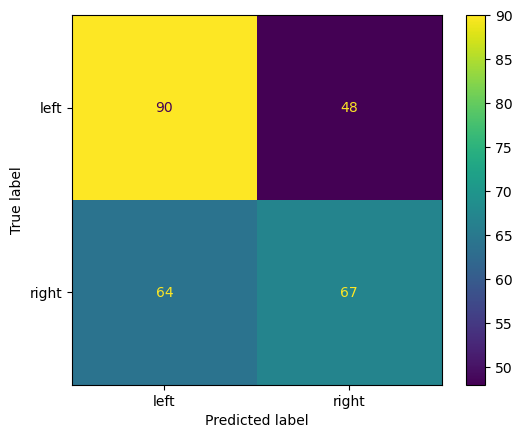

In [16]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['left', 'right'])
disp.plot()
plt.show()

## 10. Cross-validation with grouped folds

This is better for drag-level data because it respects the grouping structure.

In [17]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(model, X, y, cv=cv, groups=groups, scoring='accuracy')

print('Grouped CV scores:', cv_scores)
print('Average grouped CV accuracy:', cv_scores.mean())

Grouped CV scores: [0.57317073 0.65686275 0.65497076 0.58364312 0.64313725]
Average grouped CV accuracy: 0.622356922923563


## 11. Feature importance

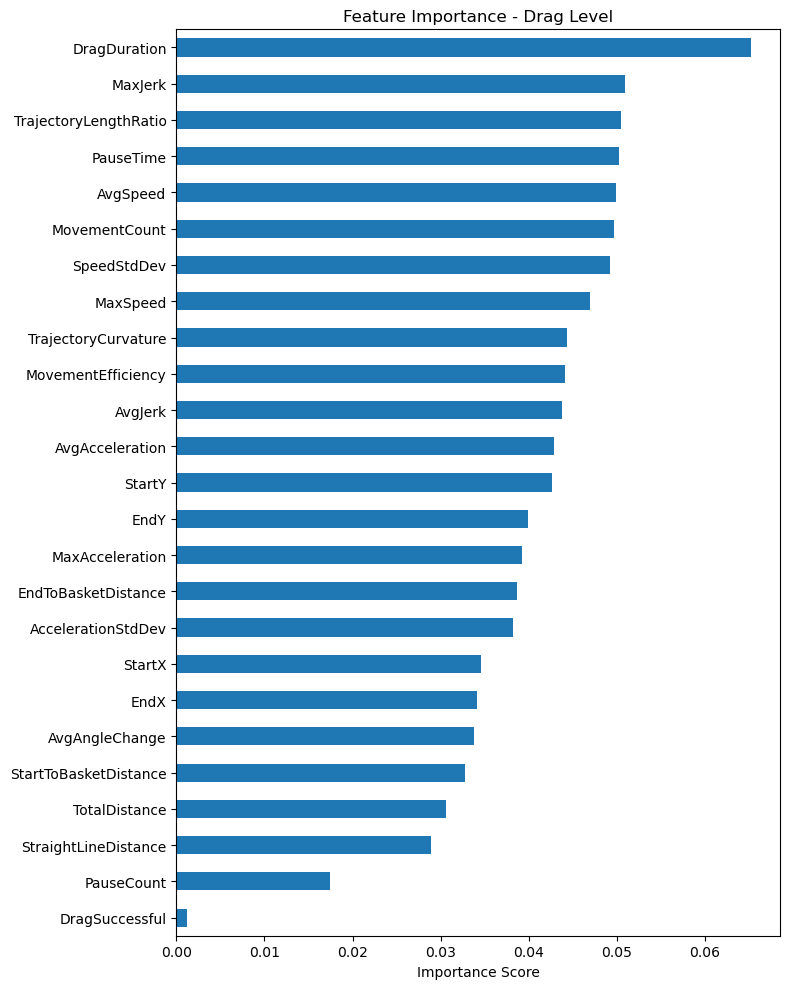

DragDuration             0.065270
MaxJerk                  0.050937
TrajectoryLengthRatio    0.050439
PauseTime                0.050295
AvgSpeed                 0.049958
MovementCount            0.049661
SpeedStdDev              0.049209
MaxSpeed                 0.046979
TrajectoryCurvature      0.044306
MovementEfficiency       0.044132
dtype: float64

In [18]:
importances = pd.Series(model.feature_importances_, index=feature_cols).sort_values(ascending=True)

plt.figure(figsize=(8, 10))
importances.plot(kind='barh')
plt.title('Feature Importance - Drag Level')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

importances.sort_values(ascending=False).head(10)

## 12. Optional: aggregate drag-level data by attempt

This creates one row per attempt using statistics from the drag-level rows. It can sometimes be more stable than using raw drag rows directly.

In [ ]:
agg_features = [
    'DragDuration', 'TotalDistance', 'TrajectoryLengthRatio', 'MovementEfficiency',
    'AvgSpeed', 'MaxSpeed', 'AvgAcceleration', 'MaxAcceleration',
    'AvgJerk', 'MaxJerk', 'AvgAngleChange', 'TrajectoryCurvature',
    'PauseCount', 'PauseTime', 'MovementCount', 'StartToBasketDistance', 'EndToBasketDistance'
]

agg_df = df.groupby('AttemptID').agg({
    **{col: ['mean', 'std', 'max'] for col in agg_features},
    'Label': 'first',
    'Handedness': 'first'
})

agg_df.columns = ['_'.join(col).strip('_') for col in agg_df.columns]
agg_df = agg_df.reset_index()
agg_df.head()

## 13. Simple conclusion

In [ ]:
print('This drag-level model predicts left vs right hand using mouse movement features from individual drags.')
print('The grouped split by AttemptID helps reduce leakage and makes the evaluation more realistic.')
print('As more data is collected, the model should become more stable and accurate.')